# **Module - 1 - False Positives**

In [1]:
# importing necessary libraries
import numpy as np
import pandas as pd

In [2]:
# function to generate population
def generate_population(population_size, vaccinated_coverage = 0.70, disease_prob_not_vaccinated = 0.80, disease_prob_vaccinated = 0.15):
  # 70% of the population are vaccinated
  num_vaccinated = int(population_size * vaccinated_coverage)
  num_not_vaccinated = population_size - num_vaccinated
  # generating vaccinated status
  vaccinated_array = np.array([1] * num_vaccinated + [0] * num_not_vaccinated)
  np.random.shuffle(vaccinated_array)
  # generating disease status
  affected_array = np.array([np.random.choice([1,0], p = [disease_prob_vaccinated, 1 - disease_prob_vaccinated]) if v == 1
                       else np.random.choice([1,0], p = [disease_prob_not_vaccinated, 1 - disease_prob_not_vaccinated])
                       for v in vaccinated_array])
  # creating population array frim vaccinated_array and affected_array
  population = np.column_stack((vaccinated_array.reshape(-1, 1), affected_array.reshape(-1, 1)))

  return population

In [3]:
# disease checker function
def disease_checker(population, prob_detect_affected = 0.80, prob_detect_unaffected = 0.75):
  detected_affected = []
  detected_unaffected = []
  for i, (_, affected) in enumerate(population):
    if affected == 1:
      detected = np.random.choice([1,0], p = [prob_detect_affected, 1 - prob_detect_affected])
    else:
      detected = np.random.choice([1,0], p = [prob_detect_unaffected, 1 - prob_detect_unaffected])
    if detected == 1:
      detected_affected.append(i)
    else:
      detected_unaffected.append(i)
  return detected_affected, detected_unaffected

In [4]:
# function to calculate probabilities
def calculate_probabilities(population, detected_affected, detected_unaffected):
    total_detected_affected = len(detected_affected)
    total_detected_unaffected = len(detected_unaffected)

    vaccinated_in_detected_affected = sum(population[i][0] == 1 for i in detected_affected)
    vaccinated_in_detected_unaffected = sum(population[i][0] == 1 for i in detected_unaffected)

    non_vaccinated_in_detected_affected = sum(population[i][0] == 0 for i in detected_affected)
    non_vaccinated_in_detected_unaffected = sum(population[i][0] == 0 for i in detected_unaffected)

    affected_in_detected_affected = sum(population[i][1] == 1 for i in detected_affected)
    affected_in_detected_unaffected = sum(population[i][1] == 1 for i in detected_unaffected)

    unaffected_in_detected_affected = sum(population[i][1] == 0 for i in detected_affected)
    unaffected_in_detected_unaffected = sum(population[i][1] == 0 for i in detected_unaffected)

    # "given_affected" it means, machine detected is affected, same for unaffected

    # (a) Probability that a person identified as affected is vaccinated
    prob_vaccinated_given_affected = vaccinated_in_detected_affected / total_detected_affected if total_detected_affected > 0 else 0

    # (b) Probability that a person identified as not affected is not vaccinated
    prob_not_vaccinated_given_unaffected = non_vaccinated_in_detected_unaffected / total_detected_unaffected if total_detected_unaffected > 0 else 0

    # (c) Probability that a person identified as not affected has actually been affected
    prob_affected_given_unaffected = affected_in_detected_unaffected / total_detected_unaffected if total_detected_unaffected > 0 else 0

    # (d) Probability that a person identified as affected has not been affected
    prob_unaffected_given_affected = unaffected_in_detected_affected / total_detected_affected if total_detected_affected > 0 else 0

    # (e) Probability that a person identified as affected is actually affected
    prob_affected_given_affected = affected_in_detected_affected / total_detected_affected if total_detected_affected > 0 else 0

    return {
        "a": prob_vaccinated_given_affected,
        "b": prob_not_vaccinated_given_unaffected,
        "c": prob_affected_given_unaffected,
        "d": prob_unaffected_given_affected,
        "e": prob_affected_given_affected
    }

In [5]:
# generating and printing status of population with disease
population_size = 1000000
population = generate_population(population_size)
population_data_set = pd.DataFrame(population, columns = ['vaccinated', 'affected'])
population_data_set

,vaccinated,affected
0,1,0
1,0,1
2,1,0
3,1,0
4,1,0
...,...,...
999995,1,0
999996,1,1
999997,0,1
999998,0,1


In [7]:
# printing indices of detected affected and detected unaffected people
detected_affected, detected_unaffected = disease_checker(population)
print("Indices of detected affected people: ")
print(detected_affected)
print("Indices of detected unaffected people: ")
print(detected_unaffected)

Indices of detected affected people: 
[1, 2, 4, 5, 6, 8, 9, 10, 11, 13, 14, 15, 16, 18, 20, 22, 24, 25, 26, 28, 29, 30, 31, 32, 33, 34, 36, 37, 38, 39, 40, 42, 43, 44, 46, 47, 48, 49, 51, 55, 56, 58, 62, 65, 66, 67, 68, 70, 71, 72, 73, 75, 76, 77, 78, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 116, 117, 118, 120, 124, 125, 127, 128, 129, 130, 131, 132, 133, 135, 136, 137, 138, 139, 140, 141, 143, 145, 147, 148, 149, 150, 151, 152, 154, 155, 156, 157, 158, 159, 160, 161, 163, 164, 166, 167, 168, 169, 170, 171, 172, 174, 175, 176, 177, 178, 180, 182, 184, 186, 187, 189, 190, 192, 193, 195, 196, 198, 199, 200, 202, 203, 205, 206, 207, 208, 209, 211, 212, 213, 214, 216, 217, 218, 219, 221, 223, 224, 225, 226, 227, 228, 229, 230, 232, 233, 234, 235, 236, 237, 238, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 254, 255, 256, 258, 260, 261, 262, 263, 264, 265, 267, 268, 26

In [8]:
# printing probabilities for the following scenarios

'''
(a) Find the probability that a person who has been identified as affected is vaccinated.
(b) Find the probability that a person who has been identified as not affected is not vaccinated.
(c) Find the probability that a person who has been identified as not affected has actually been affected.
(d) Find the probability that a person who has been identified as affected has not been affected.
(e) Find the probability that a person who has been identified as affected is actually affected.
'''
# we can get almost accurate correct probabilities of each quesion above when population is very large (some tens of lakhs or some crores)

probabilities = calculate_probabilities(population, detected_affected, detected_unaffected)
print("1.Probability that a person identified as affected is vaccinated                  : ", probabilities["a"])
print("2.Probability that a person identified as not affected is not vaccinated          : ", probabilities["b"])
print("3.Probability that a person identified as not affected has actually been affected : ", probabilities["c"])
print("4.Probability that a person identified as affected has not been affected          : ", probabilities["d"])
print("5.Probability that a person identified as affected is actually affected           : ", probabilities["e"])

1.Probability that a person identified as affected is vaccinated                  :  0.6907668831177293
2.Probability that a person identified as not affected is not vaccinated          :  0.26954144294797117
3.Probability that a person identified as not affected has actually been affected :  0.29552361996552334
4.Probability that a person identified as affected has not been affected          :  0.6400083922025492
5.Probability that a person identified as affected is actually affected           :  0.3599916077974508


# **Module - 2 - Benford's Law**

In [9]:
#importing necessary libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [10]:
# function to get the first digit of a number
def first_digit(number):
  while number >=10:
    number = number//10
  return number

In [11]:
# function to return population array of a specified year
def get_population_array(df, year):
    if year in df.columns:
        population = df[year].dropna().to_numpy(dtype=int)
        return population
    else:
        return None

In [12]:
# function to return a list of frequencies of digits of a particular year
def freq_of_digits(df, year):
    population = get_population_array(df, year)
    freq = np.array([0]*10)
    for i in population:
      freq[first_digit(i)] += 1
    return freq/sum(freq)

In [13]:
# function to return a list of count of digit occurs of a particular year
def count_of_digits(df, year):
    population = get_population_array(df, year)
    count = np.array([0]*10)
    for i in population:
      count[first_digit(i)] += 1
    return count

In [14]:
# function to find out probability of a digit using Benford's Law
def benford_prob(digit):
  return np.log10(1+1/digit)

In [15]:
#loading data set into data varaible
data = pd.read_csv('/content/world_population.csv')

In [16]:
# theoretical probabilities of digits
theory_prob = [benford_prob(i) for i in range(1, 10)]

In [17]:
# digits array
digits = np.arange(0,10)
# years list
years = [1970,1980,1990,2000,2010,2015,2020,2022]

In [18]:
# creating DataFrame showing how many time a particular digit occurs year-wise
a = pd.DataFrame(count_of_digits(data, "1970 Population"), columns=["1970"])
for i in range(1,8):
  b = pd.DataFrame(count_of_digits(data, str(years[i]) + " Population"), columns=[str(years[i])])
  count_table = pd.concat([a,b], axis=1)
  a = count_table
count_table = (count_table.drop(index=0)).T
count_table

,1,2,3,4,5,6,7,8,9
1970,57,45,28,20,32,20,8,13,11
1980,65,32,33,21,20,21,17,11,14
1990,65,37,28,25,26,13,16,11,13
2000,69,35,28,25,21,19,12,19,6
2010,66,40,31,23,21,16,12,11,14
2015,69,38,35,21,21,15,13,10,12
2020,71,35,34,22,26,18,8,10,10
2022,69,35,35,22,27,17,8,10,11


In [19]:
# creating DataFrame showing relative frequencies of digits year-wise
a = pd.DataFrame(freq_of_digits(data, "1970 Population"), columns=["1970"])
for i in range(1,8):
  b = pd.DataFrame(freq_of_digits(data, str(years[i]) + " Population"), columns=[str(years[i])])
  freq_table = pd.concat([a,b], axis=1)
  a =   freq_table
freq_table = (freq_table.drop(index=0)).T
freq_table

,1,2,3,4,5,6,7,8,9
1970,0.243590,0.192308,0.119658,0.085470,0.136752,0.085470,0.034188,0.055556,0.047009
1980,0.277778,0.136752,0.141026,0.089744,0.085470,0.089744,0.072650,0.047009,0.059829
1990,0.277778,0.158120,0.119658,0.106838,0.111111,0.055556,0.068376,0.047009,0.055556
2000,0.294872,0.149573,0.119658,0.106838,0.089744,0.081197,0.051282,0.081197,0.025641
2010,0.282051,0.170940,0.132479,0.098291,0.089744,0.068376,0.051282,0.047009,0.059829
2015,0.294872,0.162393,0.149573,0.089744,0.089744,0.064103,0.055556,0.042735,0.051282
2020,0.303419,0.149573,0.145299,0.094017,0.111111,0.076923,0.034188,0.042735,0.042735
2022,0.294872,0.149573,0.149573,0.094017,0.115385,0.072650,0.034188,0.042735,0.047009


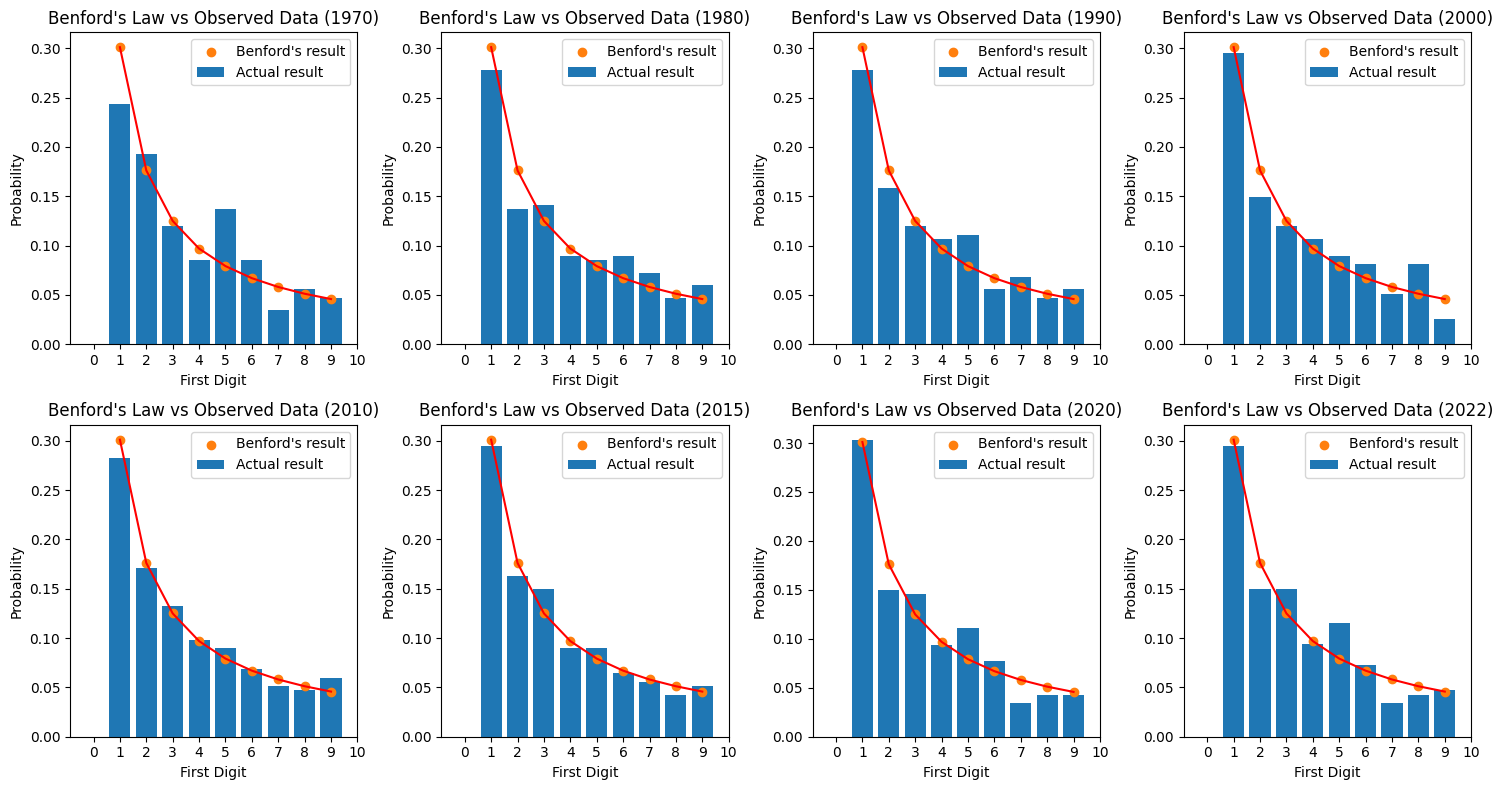

In [20]:
# creating plots (bars and scatter comparison) for each year and comparing it with Benford's distribution
fig, axes = plt.subplots(2, 4, figsize=(15, 8))

# Loop through the years and axes to plot each one
for i in range(8):
    ax = axes[i // 4, i % 4]  # Get the corresponding subplot
    ax.bar(digits, freq_of_digits(data, str(years[i]) + " Population"), label = "Actual result")
    ax.scatter(digits[1:], theory_prob, label = "Benford's result")
    ax.plot(digits[1:], theory_prob, color="r")

    ax.set_xticks(range(11))  # Set x-axis labels from 0 to 10
    ax.set_xlabel("First Digit")
    ax.set_ylabel("Probability")
    ax.set_title(f"Benford's Law vs Observed Data ({years[i]})")
    ax.legend()

plt.tight_layout()
plt.show()

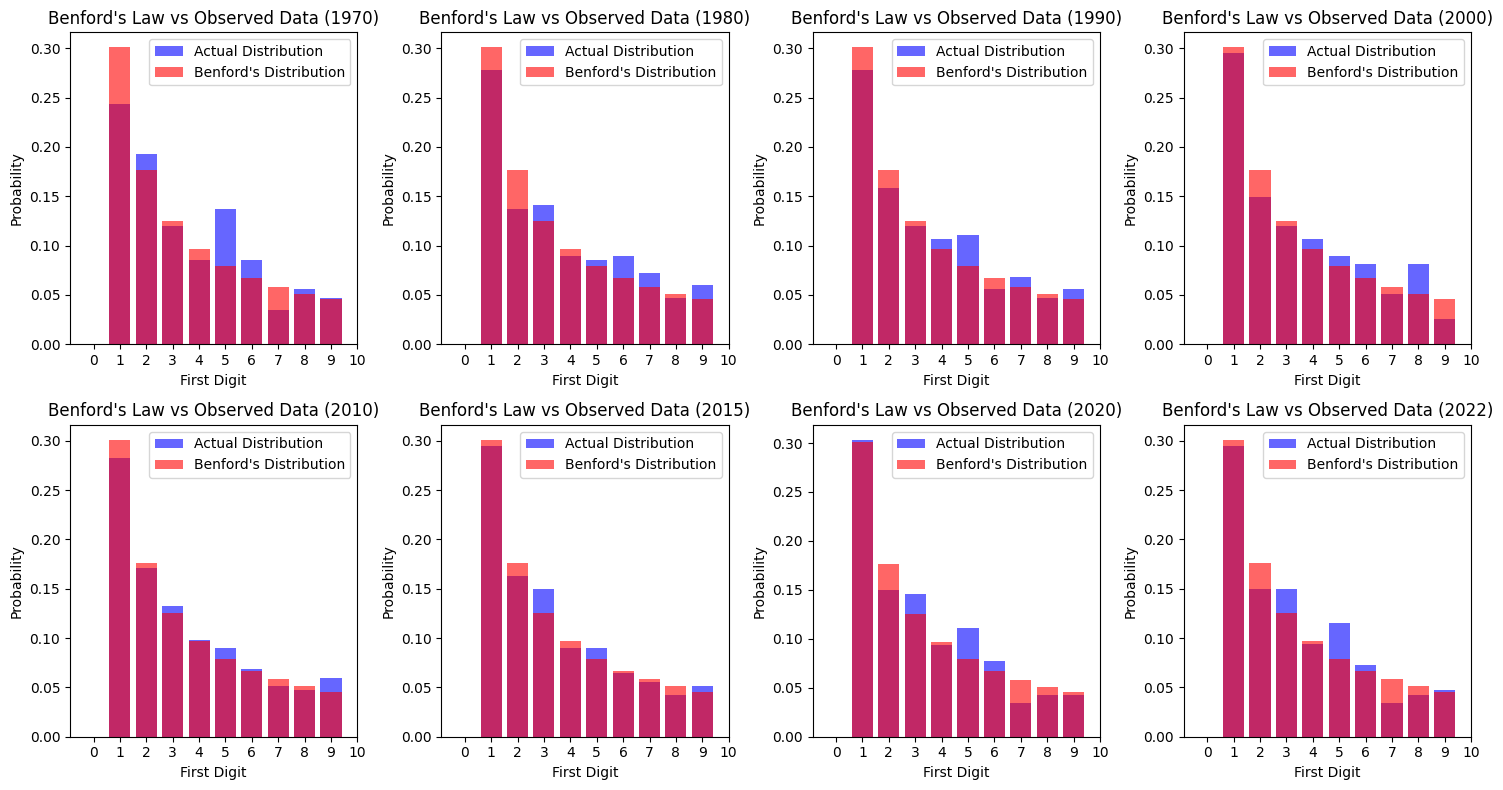

In [21]:
# creating plots (bar on bar comparison) for each year and comparing it with Benford's distribution
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for i in range(8):
    ax = axes[i // 4, i % 4]
    # Plot actual distribution as blue bars
    ax.bar(digits, freq_of_digits(data, str(years[i]) + " Population"), label="Actual Distribution", color="b", alpha=0.6)
    # Plot Benford's theoretical probabilities as red bars
    ax.bar(digits[1:], theory_prob,label="Benford's Distribution", color="red", alpha=0.6)
    ax.set_xticks(range(11))
    ax.set_xlabel("First Digit")
    ax.set_ylabel("Probability")
    ax.set_title(f"Benford's Law vs Observed Data ({years[i]})")
    ax.legend()
plt.tight_layout()
plt.show()

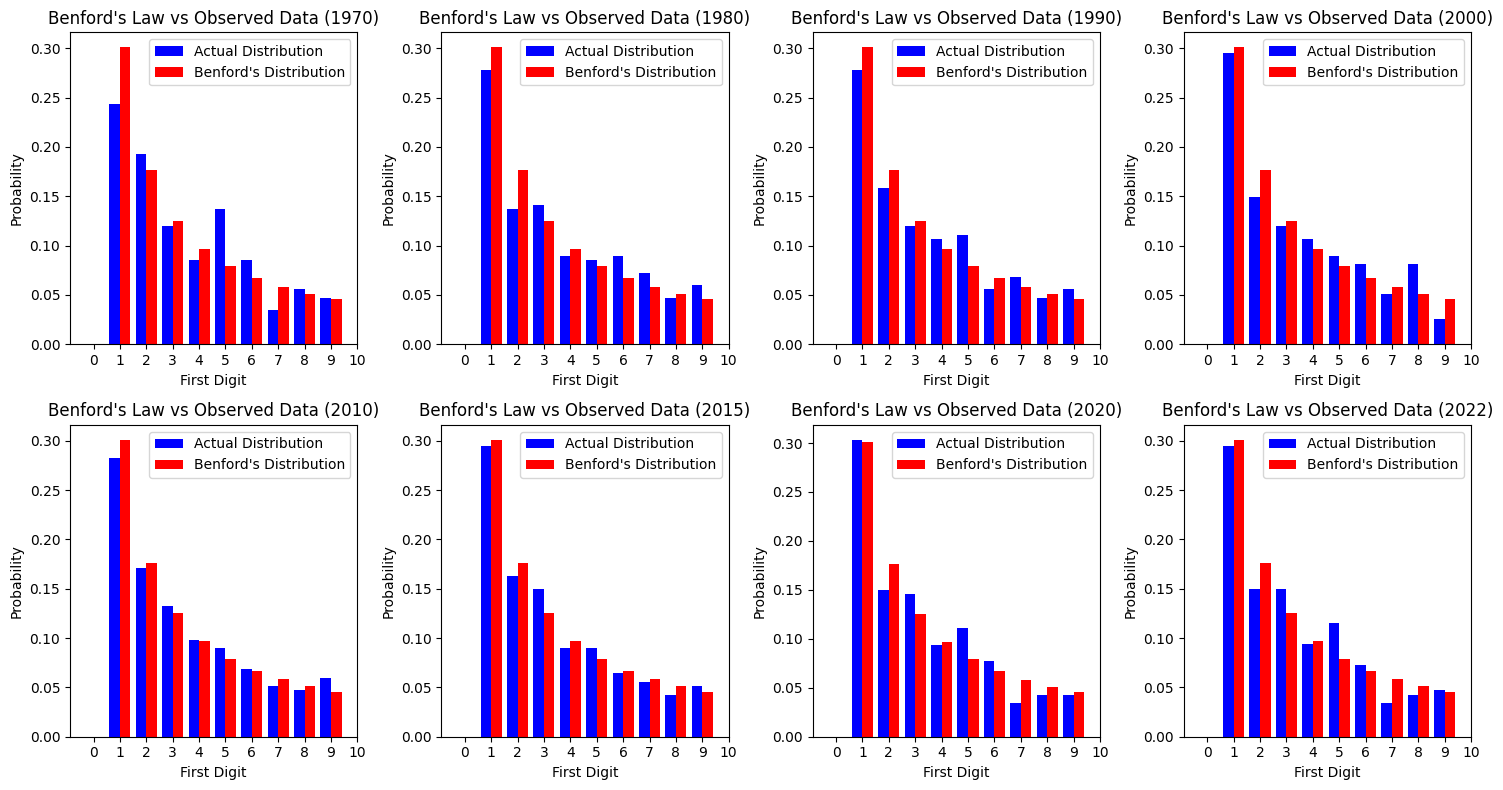

In [22]:
# creating plots (side by side bars comparison) for each year and comparing it with Benford's distribution
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
bar_width = 0.4
digits = np.array(digits)
for i in range(8):
    ax = axes[i // 4, i % 4]
    actual_freq = freq_of_digits(data, str(years[i]) + " Population")
    benford_freq = theory_prob
    # Left half - Actual Distribution (shift bars slightly left)
    ax.bar(digits - bar_width / 2, actual_freq, width=bar_width, label="Actual Distribution", color="b")
    # Right half - Benford's Distribution (shift bars slightly right)
    ax.bar(digits[1:] + bar_width / 2, benford_freq, width=bar_width, label="Benford's Distribution", color="r")
    ax.set_xticks(range(11))
    ax.set_xlabel("First Digit")
    ax.set_ylabel("Probability")
    ax.set_title(f"Benford's Law vs Observed Data ({years[i]})")
    ax.legend()
plt.tight_layout()
plt.show()